<a href="https://colab.research.google.com/github/AnanyaAdireddy0828/ml-cla3/blob/main/ml_cla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [14]:
uploaded = files.upload()

train_df = pd.read_csv("crop_yield_train.csv")
test_df = pd.read_csv("crop_yield_test.csv")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Saving crop_yield_test.csv to crop_yield_test (1).csv
Saving crop_yield_train.csv to crop_yield_train (1).csv
Training dataset shape: (4800, 18)
Testing dataset shape: (1200, 17)


In [15]:
target_column = "yield_tpha"

train_df = train_df.drop_duplicates()
train_df = train_df.dropna(subset=[target_column])

# Convert harvest date into month
for df in [train_df, test_df]:
    df["harvest_date"] = pd.to_datetime(
        df["harvest_date"], errors="coerce"
    )
    df["harvest_month"] = df["harvest_date"].dt.month

# Remove identifier columns and raw date
exclude_columns = [
    "id", "field_id", "harvest_date"
]

feature_columns = [
    col for col in train_df.columns
    if col != target_column
    and col not in exclude_columns
    and col in test_df.columns
]

X = train_df[feature_columns]
y = train_df[target_column]

X_test_final = test_df[feature_columns]

print("Target:", target_column)
print("Input features:", feature_columns)
print("Number of features:", len(feature_columns))
print("Number of records:", len(train_df))

Target: yield_tpha
Input features: ['soil_ph', 'soil_moisture', 'avg_temperature', 'total_rainfall', 'fertilizer_amount', 'pesticide_usage', 'sunlight_hours', 'nitrogen_content', 'phosphorus_content', 'potassium_content', 'irrigation_frequency', 'crop_type', 'region', 'season', 'harvest_month']
Number of features: 15
Number of records: 4800


In [16]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", X_train.shape[0])
print("Validation records:", X_val.shape[0])
print("Preprocessing completed!")

Training records: 3840
Validation records: 960
Preprocessing completed!


In [17]:
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_val)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [18]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_val)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [19]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

results = []

results.append(
    evaluate_model("Linear Regression", y_val, lr_predictions)
)

results.append(
    evaluate_model("Random Forest", y_val, rf_predictions)
)

results_df = pd.DataFrame(results)

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.523605,0.426808,0.653305,0.682943
1,Random Forest,0.538273,0.452849,0.672941,0.663598


In [20]:
comparison = pd.DataFrame({
    "Actual Yield": y_val.values,
    "Linear Regression": lr_predictions,
    "Random Forest": rf_predictions
})

display(comparison.head(10))

,Actual Yield,Linear Regression,Random Forest
0,6.324708,6.115332,6.034525
1,7.026038,7.196047,7.033855
2,5.207499,5.024980,4.798511
3,5.874830,6.453780,6.365098
4,6.028801,6.611183,6.594817
5,5.441051,4.947104,5.024098
6,5.546215,6.064782,6.115346
7,6.189774,6.109000,5.817574
8,7.801289,7.509388,7.402187
9,4.840154,6.303864,6.488720


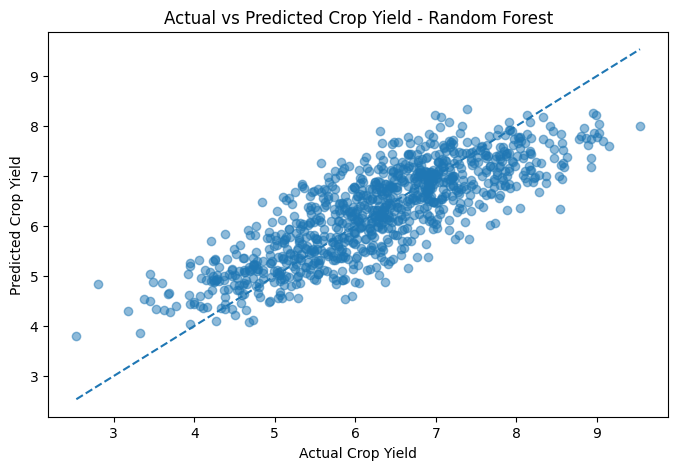

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(y_val, rf_predictions, alpha=0.5)

minimum = min(y_val.min(), rf_predictions.min())
maximum = max(y_val.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title("Actual vs Predicted Crop Yield - Random Forest")
plt.show()

In [22]:
prediction_results = pd.DataFrame({
    "Actual Yield": y_val.values,
    "Predicted Yield": rf_predictions
})

prediction_results["Absolute Error"] = abs(
    prediction_results["Actual Yield"] -
    prediction_results["Predicted Yield"]
)

print("Closest predictions:")
display(
    prediction_results.sort_values(
        "Absolute Error"
    ).head(5)
)

print("Largest prediction errors:")
display(
    prediction_results.sort_values(
        "Absolute Error",
        ascending=False
    ).head(5)
)

Closest predictions:


,Actual Yield,Predicted Yield,Absolute Error
354,6.488139,6.487007,0.001131
896,6.936379,6.938799,0.002420
171,6.728130,6.725544,0.002586
529,6.329775,6.326765,0.003010
326,7.922509,7.918361,0.004148


Largest prediction errors:


,Actual Yield,Predicted Yield,Absolute Error
846,8.547749,6.340074,2.207675
462,2.807894,4.845222,2.037328
218,8.933576,7.181639,1.751938
639,5.571382,7.267337,1.695956
117,8.047049,6.360868,1.686181


In [23]:
final_predictions = rf_model.predict(X_test_final)

submission = pd.DataFrame({
    "Predicted_Yield": final_predictions
})

display(submission.head())

submission.to_csv(
    "crop_yield_predictions.csv",
    index=False
)

files.download("crop_yield_predictions.csv")

,Predicted_Yield
0,4.243994
1,7.194988
2,7.562193
3,6.450055
4,5.850738


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>